# Value of an ABS challenge (when requested by the catcher)

Just as no hits are created equal, no ABS challenges are created either. For example if a challenge by the catcher is successful, it could mean

1. An earned strike (always true)
2. An earned out (if 2 strikes)
3. An earned win (if team is leading and 2 strikes)

On the contrary, not having a challenge available could also be costly. Suppose an umpire blew an obvious strike call. Then, not having any challenges left means:

1. A stolen ball
2. A stolen walk (if 3 balls)
3. A stolen run (if 3 balls and bases loaded)
4. A stolen lead/win (if 3 balls and bases loaded while tied in the final inning)

To put it simply, how much was lost by not having a challenge available depends on how many calls that could have been challenged could not be challenged, as well as the leverage of each call (a challenge if successful could end the game has higher leverage than a challenge if successful just gets 1 strike).

For the sake of simplicity, we will only consider how much successful challenges **positively** impacted the game.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max.columns", None)

In [2]:
data = pd.read_excel("data-train-predictions.xlsx")

In [3]:
# replay each game pitch by pitch: sort by plate appearance, then pitch within the plate appearance.
# sorted on a copy, so data keeps its original row order
games = data.sort_values(["game_id", "pa_of_game", "pitch_of_pa"])

# only a failed challenge uses one up (a successful one is kept).
# the hitting team is the away team in the top of an inning, so the home team challenged if (top) == (pitching team)
lost = ((games["is_challenge"] == 1) & (games["is_success"] == 0)).to_numpy()
by_home = (games["is_top_inning"] == (games["challenge_source"] == "pitching_team")).to_numpy()

available = np.empty((len(games), 2), dtype="int64")  # [home, away], before each pitch is (possibly) challenged
game = None
for i, (g, inning) in enumerate(zip(games["game_id"].to_numpy(), games["inning"].to_numpy())):
    if g != game:  # new game: each team starts with 2
        game, current_inning, left = g, inning, [2, 2]
    elif inning != current_inning:
        current_inning = inning
        if inning > 9:  # every extra inning gives both teams one more, capped at 2
            left = [min(n + 1, 2) for n in left]
    available[i] = left
    if lost[i]:
        left[0 if by_home[i] else 1] -= 1

# assigning a Series lines up on the index, so each value goes back to its own pitch
data["challenges_available_for_home"] = pd.Series(available[:, 0], index=games.index)
data["challenges_available_for_away"] = pd.Series(available[:, 1], index=games.index)
data[["challenges_available_for_home", "challenges_available_for_away"]].value_counts()

challenges_available_for_home  challenges_available_for_away
2                              2                                135143
1                              2                                 45883
2                              1                                 44817
1                              1                                 30904
0                              1                                 11815
1                              0                                 11810
2                              0                                 11809
0                              2                                 11079
                               0                                  5803
Name: count, dtype: int64

In [4]:
data["challenge_source_pred"] = np.where(data["challenge_source_pred"] == "hitting_team", 1, 0)
data["pitch_result"] = np.where(data["pitch_result"] == "called_strike", 1, 0)
data.head()

,play_id,venue_id,balls,strikes,outs,inning,is_top_inning,pitcher_id,pitcher_hand,batter_id,batter_hand,catcher_id,umpire_id,pitch_result,pre_score_home,pre_score_away,velocity,break_x,break_z,release_x,release_z,release_angle_x,release_angle_z,extension,plate_x,plate_z,sz_top,sz_bot,pa_of_game,pitch_of_pa,is_challenge,challenge_source,is_success,game_id,challenge_source_pred,p_challenge,p_success_g_challenge,p_challenge_in_sample,p_success_in_sample,challenges_available_for_home,challenges_available_for_away
0,c0UdVTCjQ5SUsJ89,885087,0,0,1,8,True,AOFhIJmN,Right,aL98UBkP,Right,IML0r71A,xc8EcAsU,0,4,1,89.460801,16.821696,7.641575,1.574127,4.983008,-4.832515,-0.680814,5.601144,-1.520694,1.963670,3.209,1.619,55,1,0,NaN,NaN,23411069,0,0.000066,0.026283,True,False,2,1
1,h8pmSGX80G2OMWkR,885087,2,2,1,3,True,AOFhIJmN,Right,4WzfJjoQ,Left,Lt1zY28i,yyLr2VlZ,1,0,0,87.280420,4.356654,13.543660,1.629416,4.920186,-1.887169,-1.521324,5.629167,0.264480,1.491304,3.226,1.628,19,5,0,NaN,NaN,17660261,1,0.343817,0.590569,True,False,2,2
2,6n0nKEkw0o3e2Hyp,885087,0,0,1,9,True,AOFhIJmN,Right,434FhI32,Left,IML0r71A,2zPzWXe3,0,11,6,88.743120,1.779116,13.102996,1.596064,5.016592,-2.066066,-1.694117,5.657749,-0.144320,1.486783,3.079,1.554,85,1,0,NaN,NaN,1275089,0,0.122334,0.736176,False,False,0,0
3,aAgwjqGrKTKOjn1f,491167,0,0,0,8,False,AOFhIJmN,Right,8IcFD5g6,Left,S9mCZLBI,vZTudVJV,0,4,6,88.711556,3.831993,13.076229,1.495055,4.894893,-2.602191,-1.971373,5.599896,-0.577967,1.231735,3.410,1.721,69,1,0,NaN,NaN,11359429,0,0.001227,0.078011,False,False,1,1
4,mBsYKFCsq0hvdRba,885087,2,1,1,8,True,AOFhIJmN,Right,aL98UBkP,Right,IML0r71A,xc8EcAsU,0,4,1,89.783730,15.221224,8.114938,1.498178,5.007579,-4.388744,-0.150483,5.619921,-1.312273,2.538484,3.209,1.619,55,4,0,NaN,NaN,23411069,0,0.000071,0.027597,True,False,2,1


The above dataset is simply a copy of data-train along with predictions p_challenge, p_success_g_challenge, and challenge_source. We investigate the training dataset as that is where games with game_id 01103572 lie (none exist in data-test).

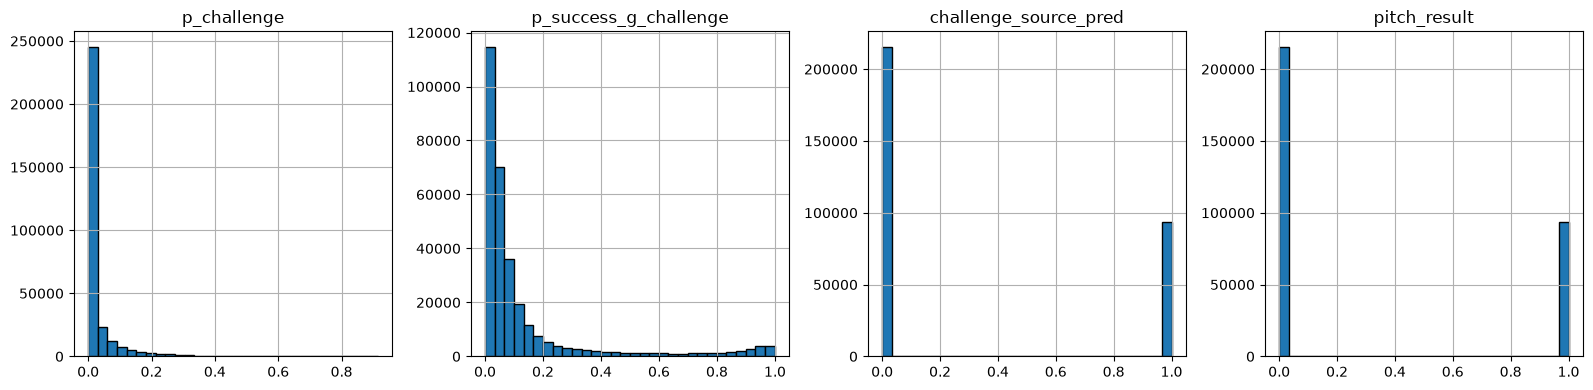

In [5]:
data[["p_challenge", "p_success_g_challenge", "challenge_source_pred", "pitch_result"]].hist(figsize=(20, 4), bins=30, layout=(-1, 5), edgecolor="black")
plt.tight_layout()
plt.show()

# Observations
- Our model (tuned XGBoost) predicts that most pitches will not be challenged, and p_success mostly agrees with this.
- We see p_challenge concentrates (skewed more right than p_success) strongly towards 0%. This makes sense as not all calls that "should be challenged", given statcast coordinates, which players don't have access to during the game, are challenged.


### Note
- We also need to remember p_challenge only tells us what pitches are likely to be challenged, not if they should be challenged. That latter questions is answered by p_success_g_challenge.

The second point suggests how we could evaluate catcher performance with regards to ABS specifically: the more catchers challenge a pitch with p_success_g_challenge above a certain threshold (say 80%), the more benefit they are getting out of ABS. That is we assume catchers who get more overturned calls with ABS are better.
To put it more formally, we should consider:

$$P(\text{challenge successful | pitch has p\_success >= T AND challenge available})$$
where $T$ is set appropriately (what appropriate means we will investigate).

We add the condition "challenge available", as if the team somehow runs out of ABS challenges (possibly not at fault of the catcher, e.g. other hitters on the team made poor challenges), the catcher should not be debited for not being able to make challenges (because they can't!).

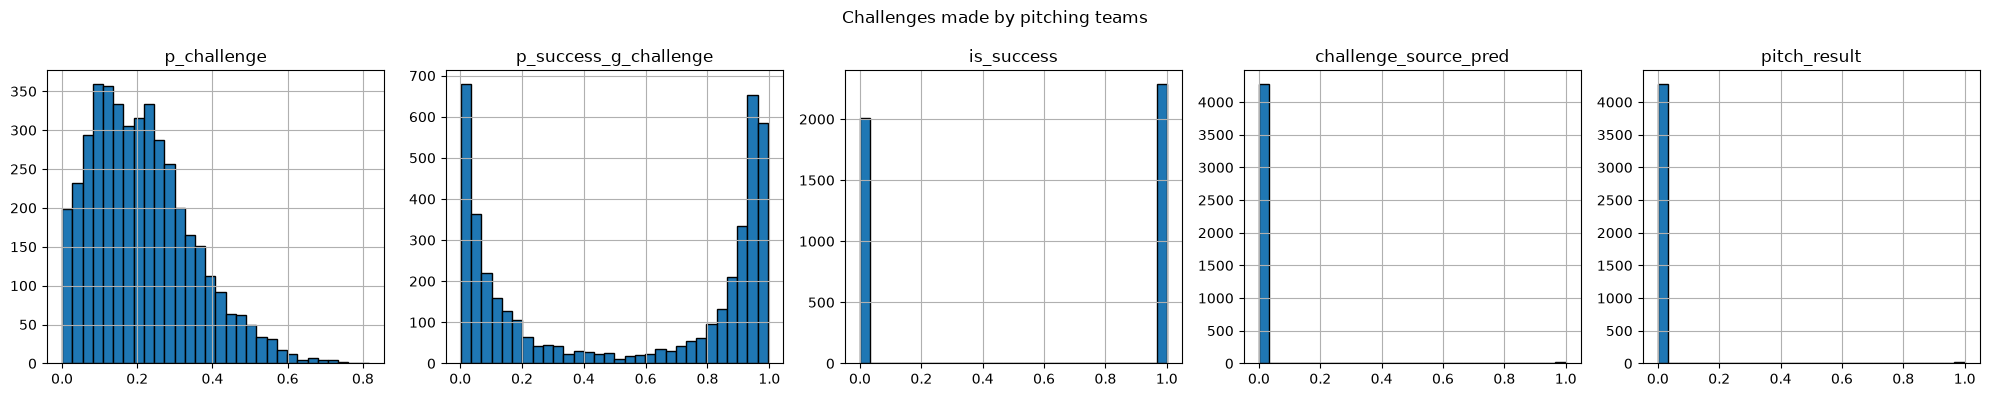

In [6]:
data.loc[(data["is_challenge"]==1)&(data["challenge_source"]=="pitching_team")][["p_challenge", "p_success_g_challenge", "is_success", "challenge_source_pred", "pitch_result"]].hist(figsize=(20, 4), bins=30, layout=(-1, 5), edgecolor="black")

plt.suptitle("Challenges made by pitching teams")
plt.tight_layout()
plt.show()

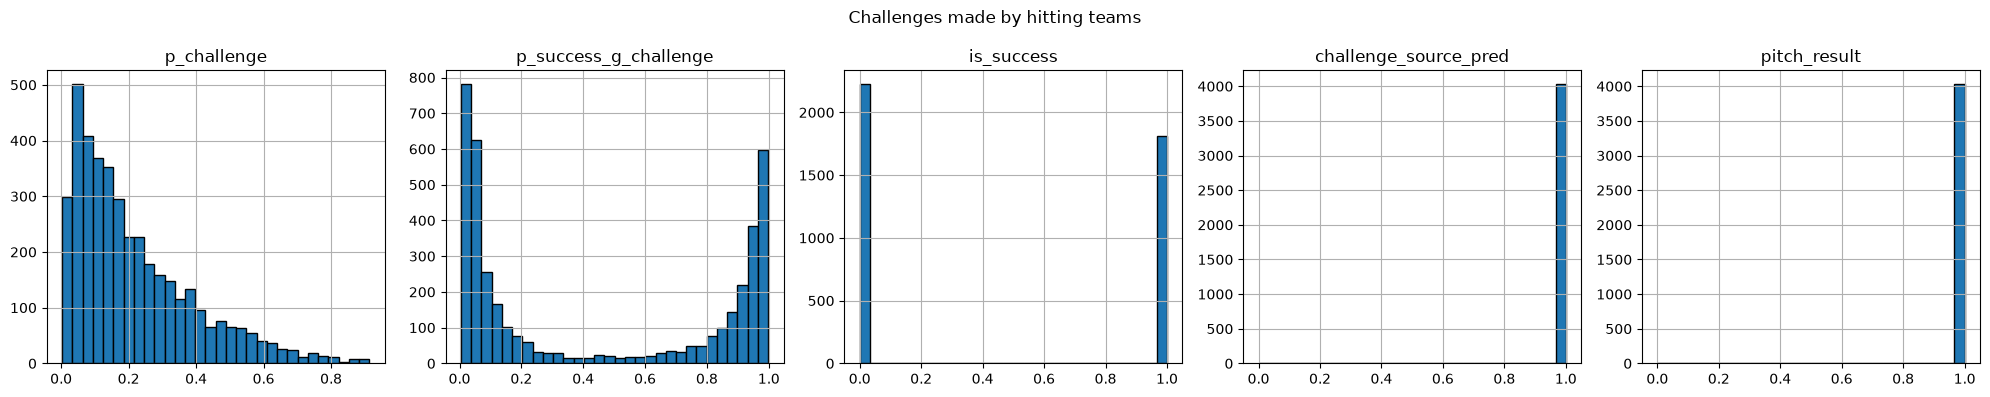

In [7]:
data.loc[(data["is_challenge"]==1)&(data["challenge_source"]=="hitting_team")][["p_challenge", "p_success_g_challenge", "is_success", "challenge_source_pred", "pitch_result"]].hist(figsize=(20, 4), bins=30, layout=(-1, 5), edgecolor="black")
plt.suptitle("Challenges made by hitting teams")
plt.tight_layout()
plt.show()

# Observations
- Our model predicts pitching teams (usually catchers) are more likely to challenge on average compared to hitters.
- Pitching teams' challenges tend to be more successful than the hitters', possibly due to catchers getting a better view of the pitch compared to hitters.

Since we want to evaluate catcher performance, we will focus on challenges made by the pitching team. We will also assume that all challenges made by the pitching team were made by catchers (as it usually is).

$$\text{For the pitching theam, let us call a called ball to be \textbf{challenge-worthy} if p\_success >= $T$.}$$

This leads us to the question: what is a reasonable threshold $T$?

We start investigating by plotting $P(\text{challenge successful | pitch has p\_success >= T})$ across a range of $T$ s

T=0.00: success_rate=0.532, #samples=4285
T=0.05: success_rate=0.664, #samples=3431
T=0.10: success_rate=0.750, #samples=3033
T=0.15: success_rate=0.811, #samples=2800
T=0.20: success_rate=0.859, #samples=2635
T=0.25: success_rate=0.888, #samples=2546
T=0.30: success_rate=0.910, #samples=2478
T=0.35: success_rate=0.929, #samples=2423
T=0.40: success_rate=0.942, #samples=2382
T=0.45: success_rate=0.957, #samples=2340
T=0.50: success_rate=0.964, #samples=2306
T=0.55: success_rate=0.969, #samples=2285
T=0.60: success_rate=0.974, #samples=2257
T=0.65: success_rate=0.980, #samples=2216
T=0.70: success_rate=0.984, #samples=2167
T=0.75: success_rate=0.987, #samples=2106
T=0.80: success_rate=0.990, #samples=2007
T=0.85: success_rate=0.992, #samples=1843
T=0.90: success_rate=0.995, #samples=1547
T=0.95: success_rate=0.998, #samples=879


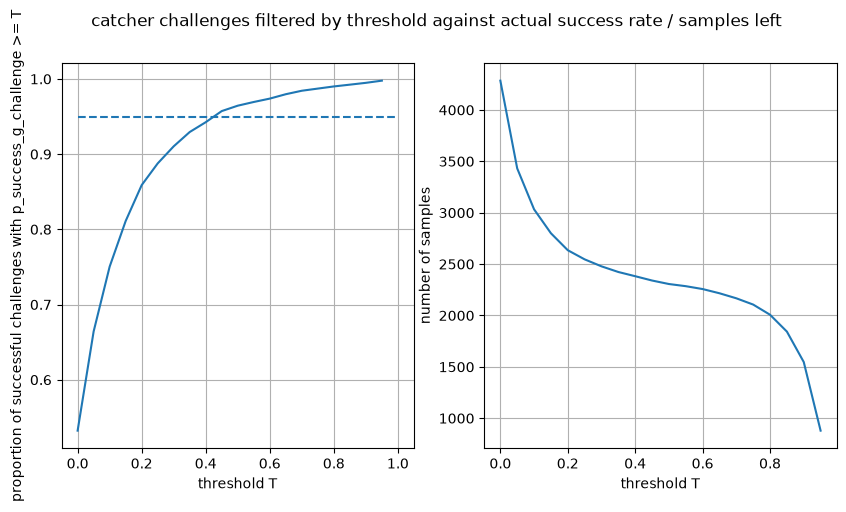

In [8]:
# for all challenged pitches with p_success > 0.8, find the sum of is_success/number of rows.
challenged_by_catcher = data.loc[(data["is_challenge"]==1)&(data["challenge_source"]=="pitching_team")]
thresholds = np.arange(0, 1, 0.05)
success_rate = []
samples_left = []
for T in thresholds:
    filtered = challenged_by_catcher.loc[(challenged_by_catcher["p_success_g_challenge"]>=T)]
    rate = filtered["is_success"].sum()/len(filtered)
    samples = len(filtered)
    print(f"T={T:.2f}: success_rate={rate:.3f}, #samples={samples}")
    success_rate.append(rate)
    samples_left.append(samples)

fig, ax = plt.subplots(1,2)

fig.set_figheight(5)
fig.set_figwidth(10)
fig.suptitle("catcher challenges filtered by threshold against actual success rate / samples left")

ax[0].plot(thresholds, success_rate)
ax[0].hlines([0.95],0,1, linestyles=["--"])
ax[0].set_xlabel("threshold T")
ax[0].set_ylabel("proportion of successful challenges with p_success_g_challenge >= T")
ax[0].grid()

ax[1].plot(thresholds, samples_left)
ax[1].set_xlabel("threshold T")
ax[1].set_ylabel("number of samples")
ax[1].grid()
plt.show()

### Observations
- Surprisingly, calls with model confidence more than $T=0.45$ have challenge success rate of 95.7%.

Since our model predicting p_success_g_challenge was fit to minimize log loss, we can reasonably assume that p_success_g_challenge reflects real probabilities (as also backed by calibration plots from p_success_g_challenge.ipynb) representing "probability the challenge would be successful if challenge requested". Combining with the fact that increasing the threshold $T$ from 0.5 to 0.8 only loses around 200 samples (5%),let us use $T=0.8$ (80% confidence by the model). 

For this evaluation, let us call a called ball by the umpire **challenge-worthy** if p_success_g_challenge >= 0.8. 

# New stats

When evaluating catchers with regards to ABS, intuitively we want to reward them for making as many **"good challenges"** as possible. Thus we propose the rate stat **Good Challenge Rate**, **Good Challenge Rate Above Average**, and **GCR+**:

$$GCR = \frac{\text{\# of \textbf{challenge-worthy} called balls challenged}}{\text{\# of \textbf{challenge-worthy} called balls seen}}$$
$$GCRAA = GCR - \text{league average } GCR$$
$$GCR+=\frac{GCR}{\text{league average } GCR}\times 100$$

### Remarks
- If the catcher requests an ABS challenge for every worthy challenge, $GCR=1$, which aligns with our expectations.
- If the catcher makes no ABS challenges at all, $GCR=0$, which seems a little harsh considering he at least didn't waste any challenges.
- To put it simply, $GCR$ measure how often the catcher was able to challenge challenge-worthy pitches.
- Since the units for $GCRAA$ is GCR (which is a rate), it might be easier to evaluate relative performance using $GCR+$, which allows us to talk about $GCR$ like any other plus stat. That is, someone who has 120 $GCR+$ is "20% better" than the average catcher in terms of making good challenges. 
 
### Exceptions
- If no pitches were flagged as **challenge-worthy**, we cannot calculate this stat.

### Limitations
- We don't separate the challenge success rate by zone. A more elaborate model could calculate the success rate for and the appropriate threshold $T$ for each zone.
- As decribed in remarks, a low GCR does not mean the catcher is actively ruining the game. Rather, it just means the catcher is not capitalizing on opportunities given by ABS.
- A catcher could also positively impact the game by "faking balls". That is, a catcher could do the opposite of framing, where they try to make a strike look like a ball, effectively baiting the hitter to challenge, wasting the opposing team's ABS challenges. This is not accounted for in GCR.
- A catcher who rarely challenges might have very high or very low GCR. This is due to noise caused by small sample size. To conuter this, we should also consider challenge success rate.
- This stat is also probably biased for catchers who catch for pitchers that throw clear strikes/balls more often. This is because whenever the calls are obvious, there is no need to challenge in the first place, and the umpire misses a clear strike, the challenge is obvious.
- Our model is not perfect. There is a chance that a pitch that should have low p_success_g_challenge gets a high score. From previous testing, we assume that this chance is very low, making this stat reliable.
- Since we don't have access to the actual names of catchers or have data on MLB catchers, we cannot test if $GCR+$ is a reliable stat that matches our intuition.

# Evaluating catchers

Given the justification above, we will be evaluating catchers's positive impact on the game by looking at:
- $GCR+$ (we will compare a catcher's season GCR+ with a single game's GCR+)
- (average) challenge success rate
- (average) calls overturned
- (average) unsuccessful challenge miss distance (given a challenge is unsuccessful, how much was it off the zone by?)
- Inning challenge available til (to which inning does a catcher have challenges available til?)

### Remarks
- The last stat is an attempt to measure how conservative a team is when it comes to ABS challenge is. Note that this is a stat for a team, not a specific catcher, as hitters can challenge too.

In [9]:
# the inning each team's challenges last until: the last inning it had one available going into a pitch
# (the inning it used up its last one, or the last inning of the game if it never ran out or got one back
# in an extra inning). this is a team stat (hitters use the same challenges), stored on every pitch for the
# team that is pitching, which is the home team in the top of the inning
home_until = data["inning"].where(data["challenges_available_for_home"]>0).groupby(data["game_id"]).max()
away_until = data["inning"].where(data["challenges_available_for_away"]>0).groupby(data["game_id"]).max()
data["challenges_until_inning"] = np.where(data["is_top_inning"], data["game_id"].map(home_until), data["game_id"].map(away_until))

In [10]:
# every stat used from here on, computed up front since the coin flip / GCR+ figure below already needs them:
# the league, season and game averages (catcher_eval), every catcher's season (by_catcher), every single game
# (per_game) and our catcher's percentiles. the tables and plots further down show them
T = 0.8
GAME = 1103572

# our catcher is the one catching the top innings, since our affiliate was the home team
our_catcher = data.loc[(data["game_id"]==GAME) & data["is_top_inning"], "catcher_id"].unique()
assert len(our_catcher) == 1
our_catcher = our_catcher[0]

# called balls the catcher should challenge, if their team still has a challenge available
# (the catcher's team is the home team in the top of the inning)
challenge_available = np.where(data["is_top_inning"], data["challenges_available_for_home"], data["challenges_available_for_away"]) > 0
worthy = (data["pitch_result"]==0) & (data["p_success_g_challenge"]>=T) & challenge_available
catcher_challenge = (data["is_challenge"]==1) & (data["challenge_source"]=="pitching_team")
good = catcher_challenge & worthy
overturned = catcher_challenge & (data["is_success"]==1)

PLATE_HALF = 17 / 2 / 12  # home plate is 17 in wide
BALL_R = 1.45 / 12        # baseball radius (~1.45 in)

def abs_edge_inches(df):
    # signed distance from each pitch's own ABS edge in inches (positive = outside the zone): its batter's
    # sz_top / sz_bot and the plate, plus the ball's radius, with rounded corners (a ball on the edge is inside)
    dx = df["plate_x"].abs() - PLATE_HALF
    dz = np.maximum(df["plate_z"] - df["sz_top"], df["sz_bot"] - df["plate_z"])
    return (np.hypot(dx.clip(lower=0), dz.clip(lower=0)) + np.minimum(np.maximum(dx, dz), 0) - BALL_R) * 12

# how far outside the zone the pitch was when a challenge failed (NaN on every other pitch). it can come out
# slightly negative when our zone (from the tracking data) disagrees with the ABS call
miss_distance = abs_edge_inches(data).where(catcher_challenge & (data["is_success"]==0))

counts = ["challenge-worthy pitches", "good challenges", "challenges", "calls overturned"]

def totals(rows):
    return {
        "games caught": len(data.loc[rows, ["game_id", "catcher_id"]].drop_duplicates()),
        "challenge-worthy pitches": worthy[rows].sum(),
        "good challenges": good[rows].sum(),
        "challenges": catcher_challenge[rows].sum(),
        "calls overturned": overturned[rows].sum(),
    }

def averages(rows):
    # counts are averaged per game caught. rates are averaged over the pitches/challenges they count,
    # so every challenge-worthy pitch (for GCR) and every challenge (for success rate) weighs the same
    t = totals(rows)
    avg = {c: t[c] / t["games caught"] for c in counts}
    avg["GCR"] = t["good challenges"] / t["challenge-worthy pitches"]
    avg["challenge success rate"] = t["calls overturned"] / t["challenges"]
    avg["unsuccessful challenge miss distance (in)"] = miss_distance[rows].mean()  # averaged over failed challenges
    # a team stat, so it is averaged over team-games (each team in each game counted once)
    team_games = data.loc[rows].drop_duplicates(["game_id", "is_top_inning"])
    avg["challenges available until inning"] = team_games["challenges_until_inning"].mean()
    return avg

def sds(rows):
    # how much each stat varies from one game caught to the next (standard deviation over games).
    # a game's GCR / success rate only exists if it had a challenge-worthy pitch / a challenge (0/0 is NaN),
    # so their SDs only use those games
    per_game = pd.DataFrame({
        "challenge-worthy pitches": worthy[rows],
        "good challenges": good[rows],
        "challenges": catcher_challenge[rows],
        "calls overturned": overturned[rows],
    }).groupby([data.loc[rows, "game_id"], data.loc[rows, "catcher_id"]]).sum()
    sd = per_game.std().to_dict()
    sd["GCR"] = (per_game["good challenges"] / per_game["challenge-worthy pitches"]).std()
    sd["challenge success rate"] = (per_game["calls overturned"] / per_game["challenges"]).std()
    # each game's average miss distance, for games with a failed challenge
    sd["unsuccessful challenge miss distance (in)"] = miss_distance[rows].groupby([data.loc[rows, "game_id"], data.loc[rows, "catcher_id"]]).mean().std()
    team_games = data.loc[rows].drop_duplicates(["game_id", "is_top_inning"])
    sd["challenges available until inning"] = team_games["challenges_until_inning"].std()
    return sd

league_rows = pd.Series(True, index=data.index)  # every catcher in data-train
season_rows = (data["catcher_id"]==our_catcher) & (data["game_id"]!=GAME)  # leaves this game out
game_rows = (data["catcher_id"]==our_catcher) & (data["game_id"]==GAME)

catcher_eval = pd.DataFrame({
    "league total": totals(league_rows),
    "league average": averages(league_rows),
    "league SD (game to game)": sds(league_rows),
    f"{our_catcher}, other games total": totals(season_rows),
    f"{our_catcher}, other games average": averages(season_rows),
    f"{our_catcher}, other games SD (game to game)": sds(season_rows),
    # one game, so its total and per-game counts are the same
    f"{our_catcher}, game {GAME}": totals(game_rows) | averages(game_rows),
}).T
# also right for the SD rows: GCR+ is GCR times a constant, so its SD scales by the same constant
catcher_eval["GCR+"] = catcher_eval["GCR"] / catcher_eval.loc["league average", "GCR"] * 100
catcher_eval = catcher_eval[["games caught"] + counts
                            + ["GCR", "GCR+", "challenge success rate", "unsuccessful challenge miss distance (in)",
                               "challenges available until inning"]]

# the same stats for every catcher over the season (this game left out, like the other-games rows of catcher_eval)
MIN_GAMES = 10  # catchers with only a few games caught have very noisy rates

other_games = data["game_id"]!=GAME
by_catcher = pd.DataFrame({
    "challenge-worthy pitches": worthy,
    "good challenges": good,
    "challenges": catcher_challenge,
    "calls overturned": overturned,
})[other_games].groupby(data.loc[other_games, "catcher_id"]).sum()
by_catcher["games caught"] = data[other_games].groupby("catcher_id")["game_id"].nunique()
by_catcher["GCR"] = by_catcher["good challenges"] / by_catcher["challenge-worthy pitches"]
by_catcher["GCR+"] = by_catcher["GCR"] / catcher_eval.loc["league average", "GCR"] * 100
by_catcher["challenge success rate"] = by_catcher["calls overturned"] / by_catcher["challenges"]
by_catcher["unsuccessful challenge miss distance (in)"] = miss_distance[other_games].groupby(data.loc[other_games, "catcher_id"]).mean()
# the team stat over the games each catcher caught
by_catcher["challenges available until inning"] = (data[other_games].drop_duplicates(["game_id", "catcher_id"])
                                                    .groupby("catcher_id")["challenges_until_inning"].mean())
by_catcher[counts] = by_catcher[counts].div(by_catcher["games caught"], axis=0)  # per game, like the average rows
by_catcher = by_catcher.loc[by_catcher["games caught"]>=MIN_GAMES, catcher_eval.columns]

# our catcher's percentile for each stat (100 = highest value, ties share the average of their ranks).
# the season is ranked among catchers with MIN_GAMES+ games (by_catcher). the game is ranked among
# every single game caught in the league, since one game varies far more than a season average
season_pct = by_catcher.rank(pct=True).loc[our_catcher] * 100

per_game = pd.DataFrame({
    "challenge-worthy pitches": worthy,
    "good challenges": good,
    "challenges": catcher_challenge,
    "calls overturned": overturned,
}).groupby([data["game_id"], data["catcher_id"]]).sum()
# a game's GCR / success rate / miss distance only exists if it had a challenge-worthy pitch / a challenge /
# a failed challenge, so those percentiles only rank games that had one
per_game["GCR"] = per_game["good challenges"] / per_game["challenge-worthy pitches"]
per_game["GCR+"] = per_game["GCR"] / catcher_eval.loc["league average", "GCR"] * 100
per_game["challenge success rate"] = per_game["calls overturned"] / per_game["challenges"]
per_game["unsuccessful challenge miss distance (in)"] = miss_distance.groupby([data["game_id"], data["catcher_id"]]).mean()
per_game["challenges available until inning"] = data.groupby(["game_id", "catcher_id"])["challenges_until_inning"].first()
game_pct = per_game.rank(pct=True).loc[(GAME, our_catcher)] * 100

# Distinguishing Between Accumulated Stats and Single Game Stats

In most cases, single game stats are far noisier thatn single game stats. That is, we cannot make reliable conclusions about a player's performance off of single game stats.


- Consider a hyopthetical stat where stat where it was basically a coinflp between 1 and 0, fipped once per game (the usefulness of this stat is irrelevant here). Across the season, each player's stat would converge to around 0.5. so the distribution of the single game stats would be 50% 0s and 50% 1, while for the season stat it would mostly be 0.5 (obviously there is noise here). Now, say a player rolled a 1. If we (unfairly) compare this to the season stat distribution, it would look like the player had an outlier performance, while if we compared it tothe  single game stat distribution, it would look ordianry. The difference is justified in the standard variation, which is 0.5 for the single game stat distribution and 0.05 in the season stat distribution.
- To put it simply, it is invalid to compare a stat gathered from a single game to the same stat but accumulated (usually throughout a season).

This is illustrated below:

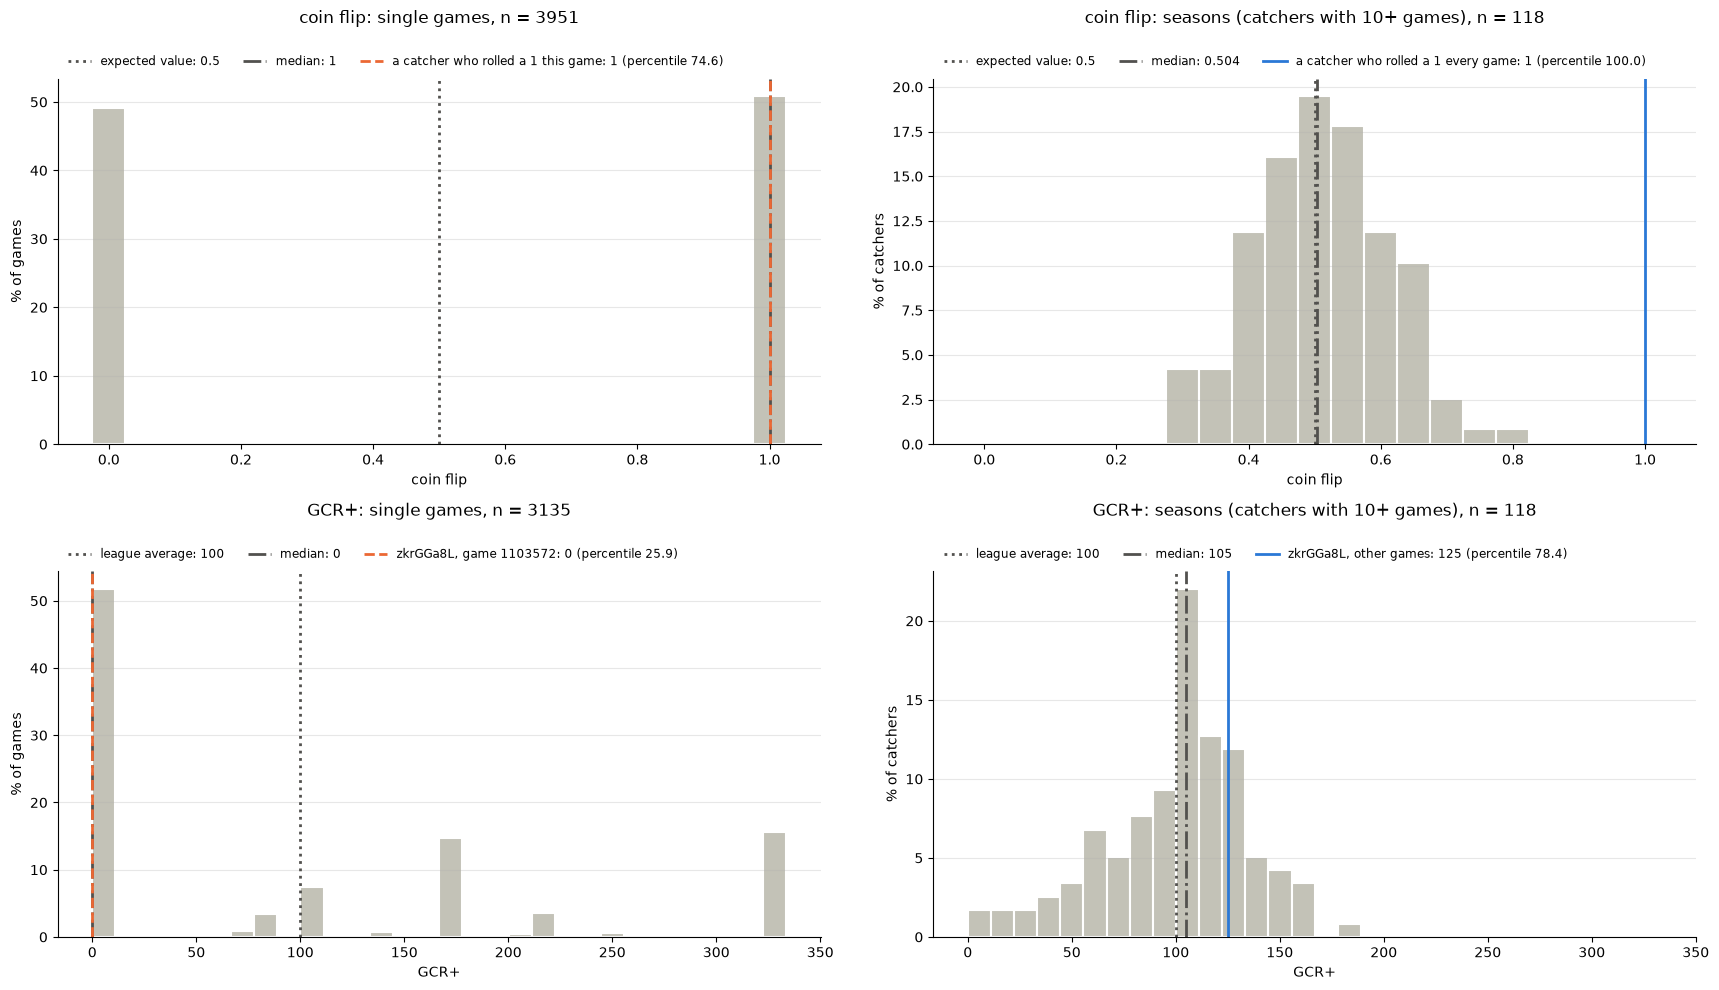

In [11]:
# why single games and seasons get separate percentiles: one game's value is spread far wider than a season average.
# top row: a made-up stat that is a coin flip (0 or 1) once per game, flipped for every catcher with MIN_GAMES+ games
# as many times as the games they caught. bottom row: the real GCR+.
# left: every single game. right: every season (the average over a catcher's games). each row shares its x-axis
rng = np.random.default_rng(0)
coin_games = by_catcher["games caught"].astype(int)
coin = pd.Series(rng.integers(0, 2, coin_games.sum()), index=np.repeat(coin_games.index, coin_games))
coin_seasons = coin.groupby(level=0).mean()

def pct_among(values, x):
    # x's percentile if it joined values, ranked the same way as the percentile table (ties share their average rank)
    return pd.concat([values, pd.Series([x])]).rank(pct=True).iloc[-1] * 100

games_gcr = per_game["GCR+"].dropna()  # every single game with a challenge-worthy pitch
seasons_gcr = by_catcher["GCR+"].dropna()  # every catcher with MIN_GAMES+ games, this game left out

rows = [
    # (values, what each value is, bins, reference lines as (value, what it is, style),
    #  line to mark, its color, its style, what it is, its percentile)
    ("coin flip", [
        (coin, "games", np.linspace(-0.025, 1.025, 22),
         [(0.5, "expected value", ":"), (coin.median(), "median", "-.")],
         1, "#eb6834", "--", "a catcher who rolled a 1 this game", pct_among(coin, 1)),
        (coin_seasons, "catchers", np.linspace(-0.025, 1.025, 22),
         [(0.5, "expected value", ":"), (coin_seasons.median(), "median", "-.")],
         1, "#2a78d6", "-", "a catcher who rolled a 1 every game", pct_among(coin_seasons, 1)),
    ]),
    ("GCR+", [
        (games_gcr, "games", np.linspace(0, games_gcr.max(), 31),
         [(100, "league average", ":"), (games_gcr.median(), "median", "-.")],
         per_game.loc[(GAME, our_catcher), "GCR+"], "#eb6834", "--", f"{our_catcher}, game {GAME}", game_pct["GCR+"]),
        (seasons_gcr, "catchers", np.linspace(0, games_gcr.max(), 31),
         [(100, "league average", ":"), (seasons_gcr.median(), "median", "-.")],
         seasons_gcr[our_catcher], "#2a78d6", "-", f"{our_catcher}, other games", season_pct["GCR+"]),
    ]),
]

fig, axes = plt.subplots(2, 2, figsize=(18, 10), sharex="row")
for ax_row, (stat, panels) in zip(axes, rows):
    for ax, (values, unit, bins, references, mark, color, style, name, pct) in zip(ax_row, panels):
        # as a share of all games / catchers, so the two panels' heights compare directly
        ax.hist(values, bins=bins, weights=np.full(len(values), 100 / len(values)), color="#c3c2b7",
                edgecolor="white", linewidth=1.5)
        for value, what, line_style in references:
            ax.axvline(value, color="#52514e", linestyle=line_style, linewidth=2, label=f"{what}: {value:.3g}")
        ax.axvline(mark, color=color, linestyle=style, linewidth=2, label=f"{name}: {mark:.3g} (percentile {pct:.1f})")
        ax.set_title(f"{stat}: {'single games' if unit == 'games' else f'seasons (catchers with {MIN_GAMES}+ games)'}"
                     f", n = {len(values)}", pad=40)
        ax.set_xlabel(stat)
        ax.set_ylabel(f"% of {unit}")
        ax.grid(axis="y", alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1), ncol=3, fontsize="small")  # above the plot, off the lines
fig.tight_layout()
plt.show()

In [12]:
# the league, season and game averages of each stat (catcher_eval, computed with the other stats further up)
catcher_eval.style.format(precision=3, na_rep="")

,games caught,challenge-worthy pitches,good challenges,challenges,calls overturned,GCR,GCR+,challenge success rate,unsuccessful challenge miss distance (in),challenges available until inning
league total,4196.000,6675.000,2001.000,4293.000,2285.000,,,,,
league average,,1.591,0.477,1.023,0.545,0.300,100.000,0.532,0.995,8.231
league SD (game to game),,1.411,0.728,0.970,0.779,0.369,123.082,0.440,1.104,1.681
"zkrGGa8L, other games total",26.000,40.000,15.000,36.000,20.000,,,,,
"zkrGGa8L, other games average",,1.538,0.577,1.385,0.769,0.375,125.094,0.556,1.010,8.500
"zkrGGa8L, other games SD (game to game)",,1.449,0.758,1.134,0.951,0.400,133.568,0.423,1.102,1.449
"zkrGGa8L, game 1103572",1.000,2.000,0.000,2.000,1.000,0.000,0.000,0.500,0.559,9.000


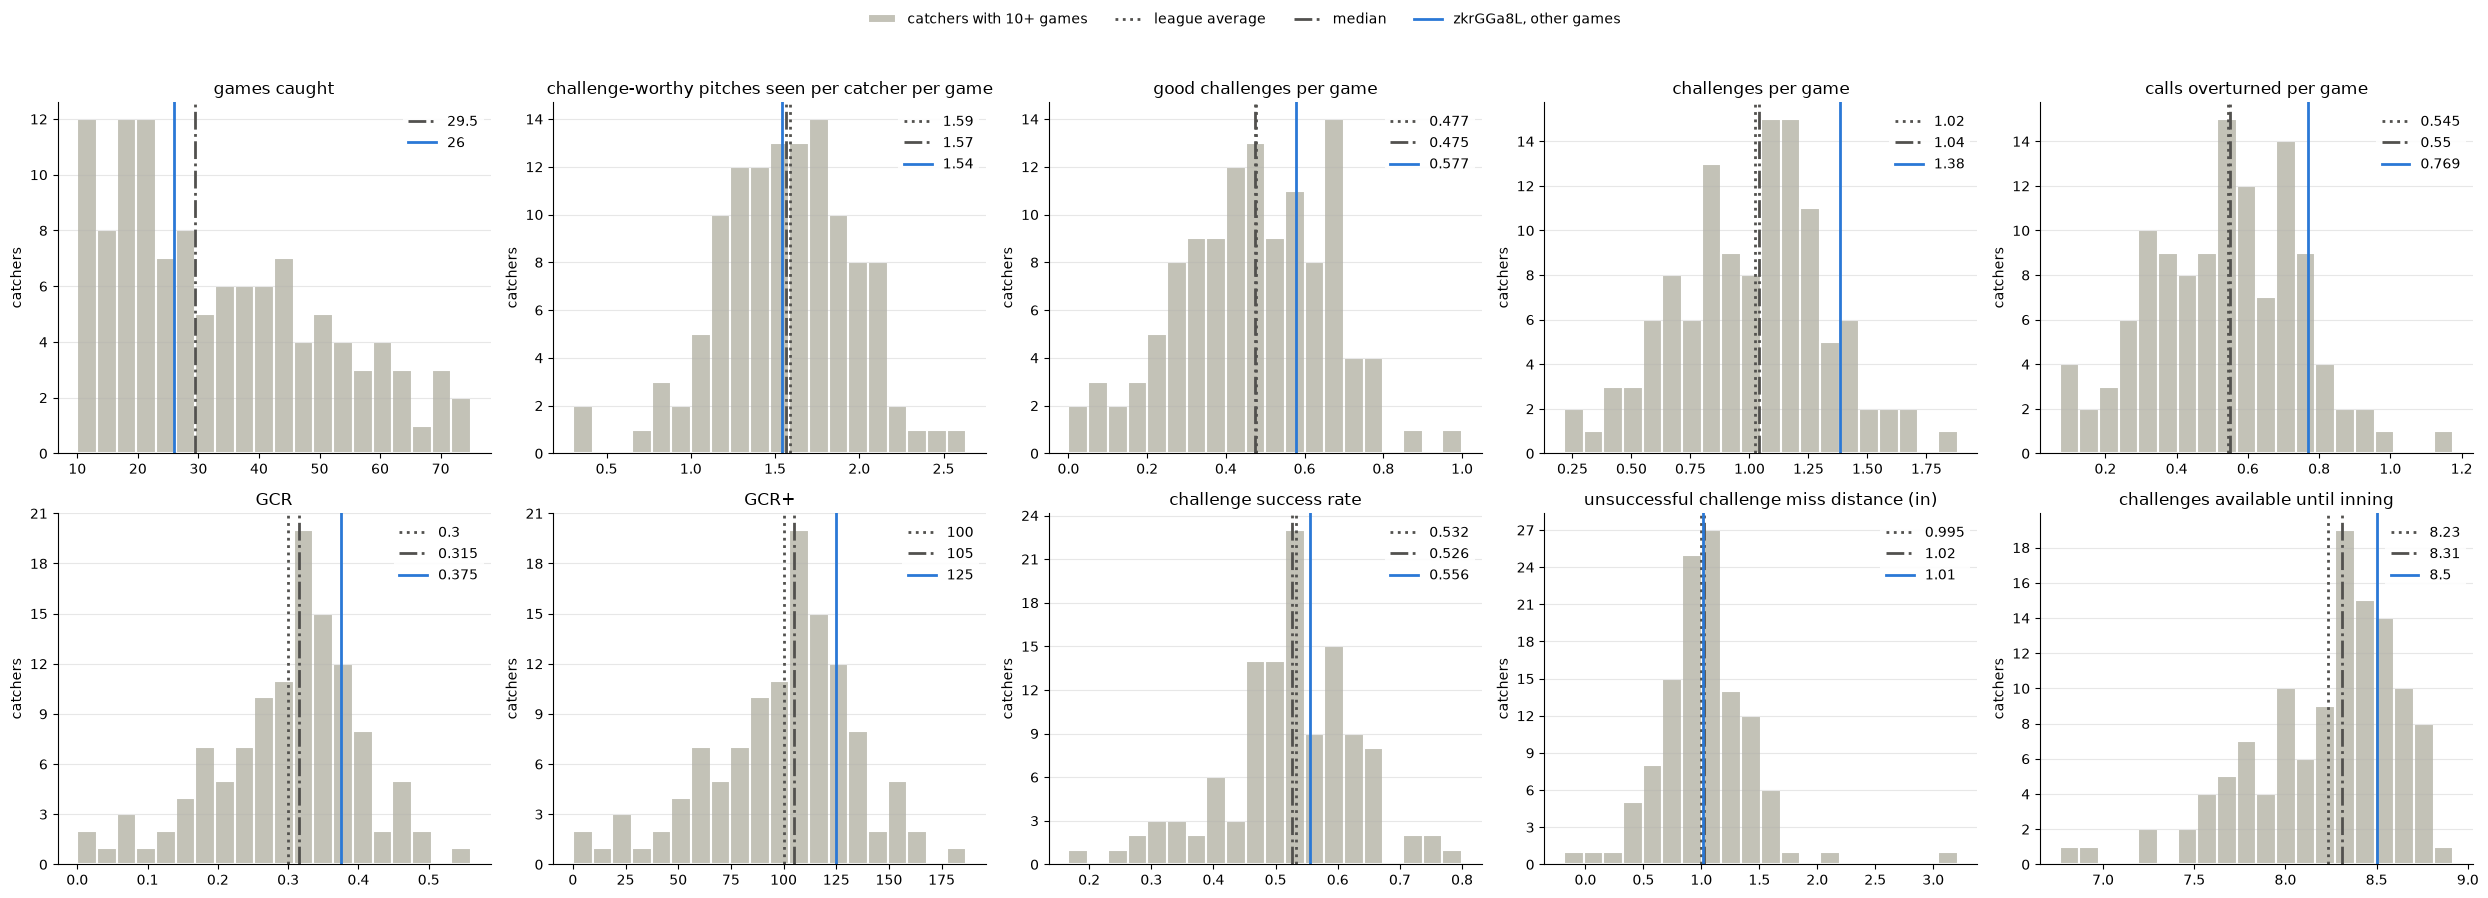

In [13]:
from matplotlib.ticker import MaxNLocator

# every catcher's season (by_catcher, computed with the other stats further up; this game left out, like the table
# above), to see where our catcher sits among the rest of the league. the game itself isn't drawn here: one game
# varies far more than a season average, so it is drawn against every single game instead (after the percentile table)
# one panel per stat, 5 to a row (unused panels hidden)
nrows = -(-len(catcher_eval.columns) // 5)
fig, axes = plt.subplots(nrows, 5, figsize=(25, 4.5 * nrows))
for ax in axes.flat[len(catcher_eval.columns):]:
    ax.set_visible(False)
titles = {"challenge-worthy pitches": "challenge-worthy pitches seen per catcher per game"}  # where the column name is unclear
for ax, stat in zip(axes.flat, catcher_eval.columns):
    ax.hist(by_catcher[stat].dropna(), bins=20, color="#c3c2b7", edgecolor="white", linewidth=1.5,
            label=f"catchers with {MIN_GAMES}+ games")
    ax.axvline(catcher_eval.loc["league average", stat], color="#52514e", linestyle=":", linewidth=2,
               label="league average")
    ax.axvline(by_catcher[stat].median(), color="#52514e", linestyle="-.", linewidth=2, label="median")
    ax.axvline(by_catcher.loc[our_catcher, stat], color="#2a78d6", linewidth=2,
               label=f"{our_catcher}, other games")
    ax.set_title(titles.get(stat, stat + (" per game" if stat in counts else "")))
    ax.set_ylabel("catchers")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    # each line's value, in the line's own style (the legend at the top says which line is which).
    # a line with no value (games caught has no league average) is left out
    shown = [line for line in ax.get_lines() if pd.notna(line.get_xdata()[0])]
    ax.legend(shown, [f"{line.get_xdata()[0]:.3g}" for line in shown], loc="best", framealpha=0.9, edgecolor="none")

handles, labels = axes.flat[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

# League Observations: Accumulated Stats
- We see that on average, a catcher sees only 1.57 challenge-worthy pitches per game. This makes sense as the vast majority of pitches are called correctly by umpires. This means a catcher's ABS performance is mainly based on whether they can capitalize on a single pitch that is miscalled.
- We see that of all challenges called by catchers, only about 46.6% of those challenges are "good challenges".
- League average GCR sits at 0.300, which means only about a third of challenge-worthy ball calls are being challenged.
- League average challenge success rate sits at 0.532, which makes sense as challenges are mostly requested for close calls (obvious ones are rarely blown by the umpire).
- League average unsuccessful challenge miss distance is about an inch.
- Most rate stats' distirbutions look unimodal.

### Remarks
- All stats that are nonempty in the "league total" row are averaged over the number of games caught (one per catcher per game) in the dataset, while the others are averaged according do their own rules.

In [14]:
# our catcher's percentile for each stat (season_pct and game_pct, computed with the other stats further up).
# 100 = highest value, ties share the average of their ranks. the season is ranked among catchers with MIN_GAMES+
# games (the plots above), the game among every single game caught in the league
percentiles = pd.DataFrame({
    f"{our_catcher}, other games (among catchers with {MIN_GAMES}+ games)": season_pct,
    f"{our_catcher}, game {GAME} (among all single games)": game_pct,
}).T[catcher_eval.columns]
percentiles.style.format(precision=1, na_rep="")

,games caught,challenge-worthy pitches,good challenges,challenges,calls overturned,GCR,GCR+,challenge success rate,unsuccessful challenge miss distance (in),challenges available until inning
"zkrGGa8L, other games (among catchers with 10+ games)",42.8,49.2,69.5,89.8,88.1,78.4,78.4,65.3,48.3,73.3
"zkrGGa8L, game 1103572 (among all single games)",,65.6,32.0,83.3,74.2,25.9,25.9,49.6,37.7,61.2


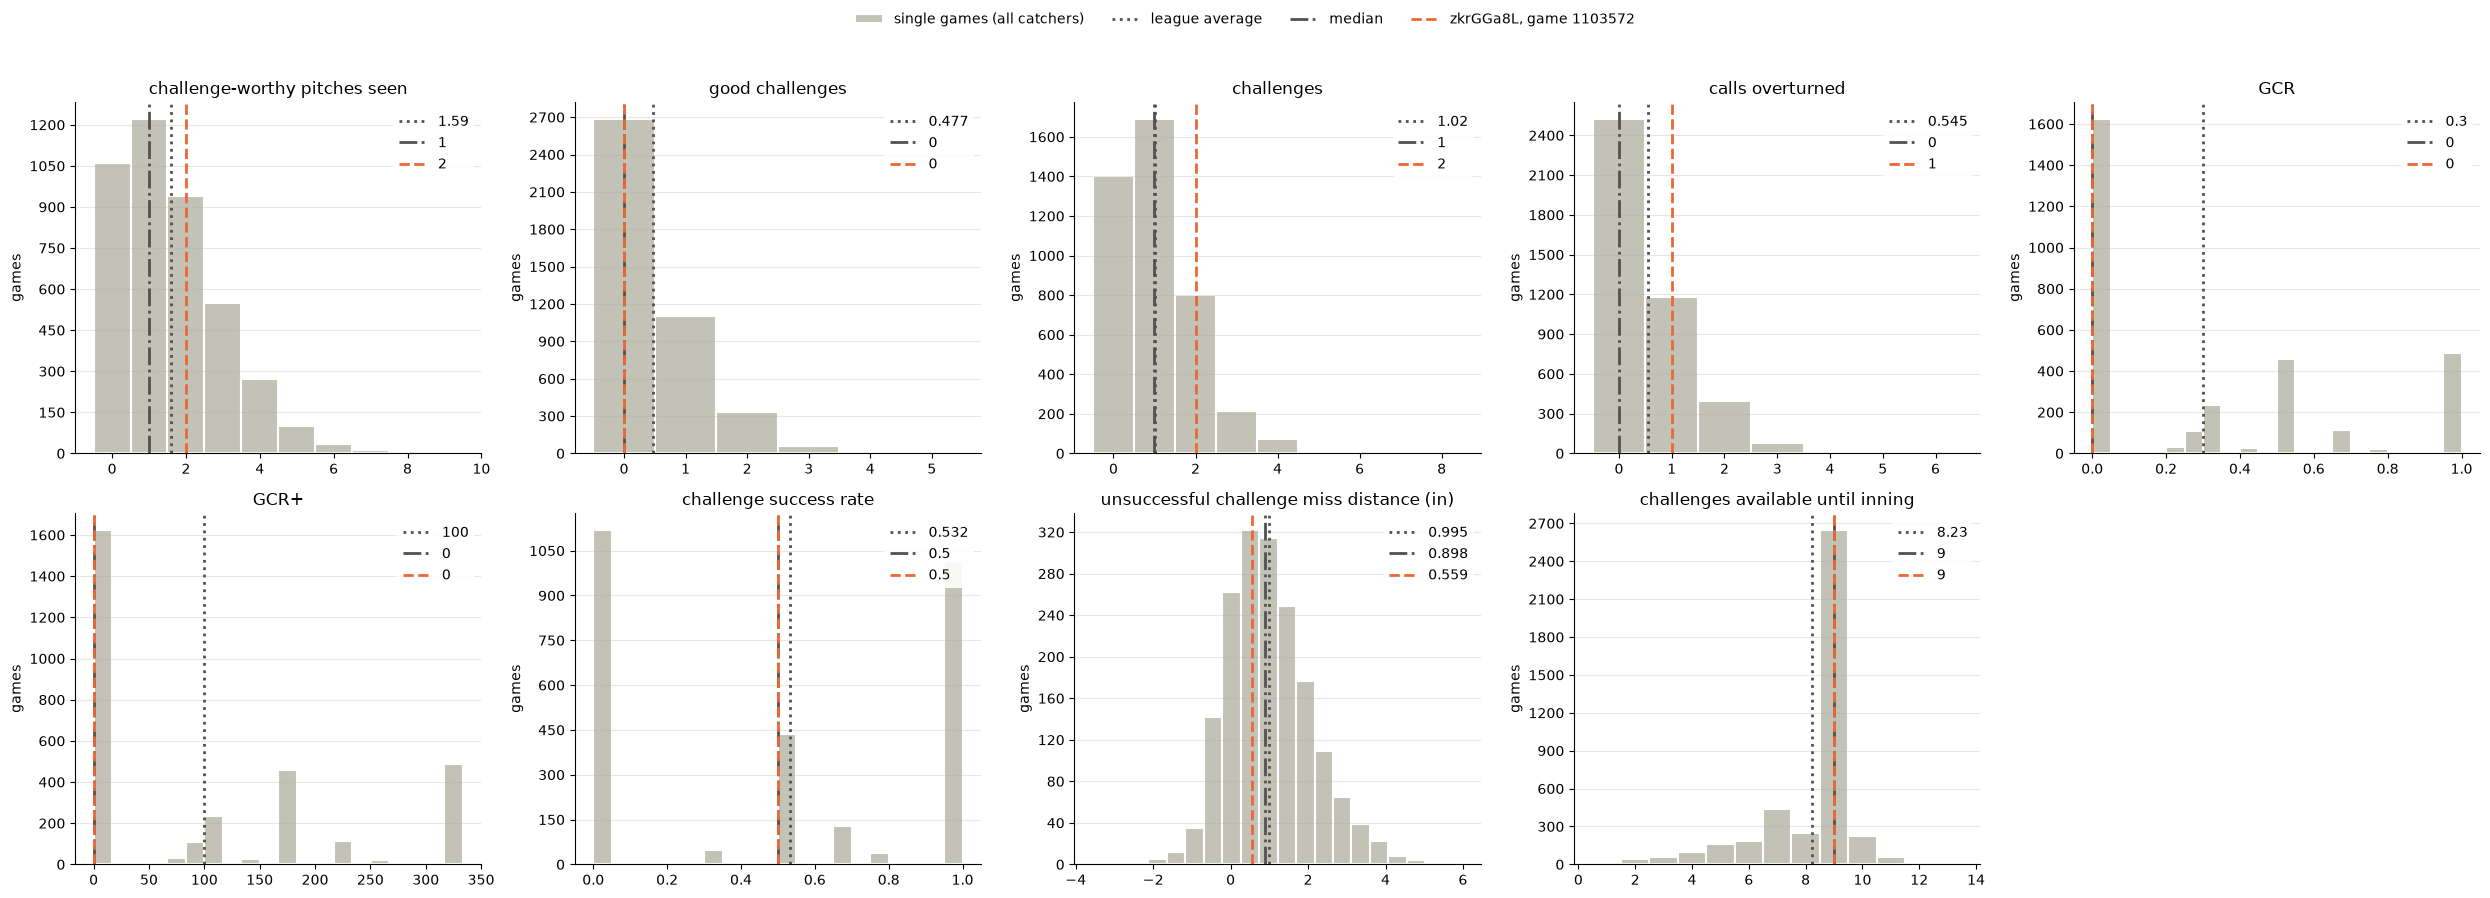

In [15]:
# every single game caught in the league (one catcher in one game), the distribution our game is ranked against
# in the percentile table. games caught is left out since it is always 1 here
game_stats = [stat for stat in catcher_eval.columns if stat != "games caught"]

nrows = -(-len(game_stats) // 5)
fig, axes = plt.subplots(nrows, 5, figsize=(25, 4.5 * nrows))
for ax in axes.flat[len(game_stats):]:
    ax.set_visible(False)
titles = {"challenge-worthy pitches": "challenge-worthy pitches seen"}  # where the column name is unclear
for ax, stat in zip(axes.flat, game_stats):
    values = per_game[stat].dropna()
    # counts and innings only take whole numbers, so they get one bar per value
    bins = np.arange(values.min() - 0.5, values.max() + 1.5) if (values % 1 == 0).all() else 20
    ax.hist(values, bins=bins, color="#c3c2b7", edgecolor="white", linewidth=1.5, label="single games (all catchers)")
    ax.axvline(catcher_eval.loc["league average", stat], color="#52514e", linestyle=":", linewidth=2,
               label="league average")
    ax.axvline(values.median(), color="#52514e", linestyle="-.", linewidth=2, label="median")
    ax.axvline(per_game.loc[(GAME, our_catcher), stat], color="#eb6834", linestyle="--", linewidth=2,
               label=f"{our_catcher}, game {GAME}")
    ax.set_title(titles.get(stat, stat))
    ax.set_ylabel("games")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    # each line's value, in the line's own style (the legend at the top says which line is which).
    # a line with no value (e.g. miss distance in a game without a failed challenge) is left out
    shown = [line for line in ax.get_lines() if pd.notna(line.get_xdata()[0])]
    ax.legend(shown, [f"{line.get_xdata()[0]:.3g}" for line in shown], loc="best", framealpha=0.9, edgecolor="none")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

# Observations specific to our catcher (zkrGGa8L)

- He has seen about the same number of challenge-worthy pitches as the league average.
- His average number of challenges per game is around 0.362 higher than the league average, meaning he is more aggresive when it comes to challenges.
- His average challenge success rate is around league average, only about 0.024 points higher than league average, placing him at 65th percentile.
- His average $GCR+$ of 125 tells us he's about 25% better than league average, which places him in the 78th percentile for $GCR+$.
- His average unsuccessful challenge miss distance is very average, at around 1 inch.

# Caveats
- The percentile for unsuccessful challenge miss distance is actually flipped. That is, the lower the percentile the better.
- Unsuccessful challenge miss distance has data points with "negative distance". We suspect this is because of mislabeled data (pitches clearly in the zone that was challenged was not overturned).
- Our catcher's $GCR+$ is from a sample of 40 challenge-worthy pitches. That is, one more good challenge increases his $GCR+$ by 8 points, meaning the stat is still quite noisy.

Therefore we conclude our catcher's single game $GCR+$ of 0 is totally ordinary.

# What actually happened in the game

In [16]:
# every called pitch of game 01103572 in the order it happened
# (pitch_result: 1 = called strike, 0 = ball, after the recoding above)
game = data.loc[data["game_id"]==1103572].sort_values(["pa_of_game", "pitch_of_pa"])
game_cols = ["inning", "is_top_inning", "pa_of_game", "pitch_of_pa", "balls", "strikes", "outs",
             "pre_score_home", "pre_score_away", "catcher_id", "pitch_result",
             "is_challenge", "challenge_source", "is_success", "p_success_g_challenge"]

with pd.option_context("display.max_rows", None):
    display(game[game_cols])

,inning,is_top_inning,pa_of_game,pitch_of_pa,balls,strikes,outs,pre_score_home,pre_score_away,catcher_id,pitch_result,is_challenge,challenge_source,is_success,p_success_g_challenge
212591,1,True,1,1,0,0,0,0,0,zkrGGa8L,1,0,NaN,NaN,0.246684
212592,1,True,1,2,0,1,0,0,0,zkrGGa8L,0,0,NaN,NaN,0.774588
212610,1,True,2,1,0,0,1,0,0,zkrGGa8L,0,0,NaN,NaN,0.060138
212611,1,True,2,2,1,0,1,0,0,zkrGGa8L,1,0,NaN,NaN,0.076853
212608,1,True,2,3,1,1,1,0,0,zkrGGa8L,0,0,NaN,NaN,0.113832
212609,1,True,2,4,2,1,1,0,0,zkrGGa8L,1,0,NaN,NaN,0.070889
47375,1,False,4,1,0,0,0,0,0,hacvQQly,0,0,NaN,NaN,0.012189
47373,1,False,4,3,1,1,0,0,0,hacvQQly,1,0,NaN,NaN,0.778544
47371,1,False,4,4,1,2,0,0,0,hacvQQly,0,0,NaN,NaN,0.011751
47423,1,False,5,4,0,2,1,0,0,hacvQQly,0,0,NaN,NaN,0.025007


In [ ]:
import plotly.graph_objects as go
from IPython.display import HTML, display

# every challenge our catcher made in the games they caught, plus the challenge-worthy pitches they let go
# and every other called ball they didn't challenge, at their real location and colored by the model's
# predicted chance the call is overturned.
# click a legend entry to show/hide it, double-click to show only that one; hover a pitch for details
decision = pd.Series(np.select(
    [catcher_challenge & (data["is_success"]==1), catcher_challenge & (data["is_success"]==0), worthy & ~catcher_challenge,
     (data["pitch_result"]==0) & ~catcher_challenge],
    ["overturned", "upheld", "not challenged", "other"], default=""), index=data.index)
caught = data[(data["catcher_id"]==our_catcher) & (decision!="")].assign(decision=decision)

INK, INK2 = "#0b0b0b", "#52514e"
sz_top, sz_bot = caught["sz_top"].median(), caught["sz_bot"].median()

def abs_edge_text(df):
    # distance from each pitch's own ABS edge (abs_edge_inches, defined with the stats above), as text
    inches = abs_edge_inches(df).round(1)
    return inches.abs().map("{:.1f} in ".format) + np.where(inches > 0, "outside", "inside")

caught["abs_edge"] = abs_edge_text(caught)
caught["half"] = np.where(caught["is_top_inning"], "top ", "bot ") + caught["inning"].astype(str)
caught["p_text"] = caught["p_success_g_challenge"].map("{:.2f}".format)  # NaN when the model had missing inputs
# break as given in the data, in inches. the pitcher's hand is shown since horizontal break mirrors between
# righties and lefties (righties are mostly positive, lefties mostly negative)
caught["break_text"] = (caught["pitcher_hand"].str[0] + "HP, " + caught["break_x"].map("{:.1f}".format)
                        + " in horizontal, " + caught["break_z"].map("{:.1f}".format) + " in vertical")

fig = go.Figure()
n_other = data.loc[(data["catcher_id"]==our_catcher) & (data["game_id"]!=GAME), "game_id"].nunique()
for in_game, group, size in [(True, f"Game {GAME}", 12), (False, f"Other games caught ({n_other})", 8)]:
    for kind, symbol, label in [("overturned", "circle", "challenged, overturned"),
                                ("upheld", "circle-open", "challenged, upheld"),
                                ("not challenged", "x", f"challenge-worthy (p ≥ {T}), not challenged"),
                                ("other", "diamond", "other called balls, not challenged")]:
        pts = caught[((caught["game_id"]==GAME)==in_game) & (caught["decision"]==kind)]
        # the other called balls are many and mostly nowhere near the edge: small, faded, and hidden until clicked
        background = kind == "other"
        fig.add_trace(go.Scatter(
            x=pts["plate_x"], y=pts["plate_z"], mode="markers",
            name=f"{label} ({len(pts)})", legendgroup=group, legendgrouptitle_text=group,
            visible="legendonly" if background else True, opacity=0.5 if background else 1,
            marker=dict(color=pts["p_success_g_challenge"], coloraxis="coloraxis", symbol=symbol,
                        size=5 if background else size, line=dict(width=1.5)),
            customdata=np.stack([pts["game_id"], pts["half"], pts["balls"].astype(str) + "-" + pts["strikes"].astype(str),
                                 pts["outs"], pts["pre_score_home"].astype(str) + "-" + pts["pre_score_away"].astype(str),
                                 pts["challenges_available_for_home"].astype(str) + "-" + pts["challenges_available_for_away"].astype(str),
                                 pts["p_text"], pts["abs_edge"], pts["play_id"],
                                 pts["break_text"], pts["sz_top"], pts["sz_bot"]], axis=1),
            hovertemplate=(f"<b>{label}</b> (called ball)<br>predicted P(overturned) %{{customdata[6]}}"
                           "<br>game %{customdata[0]}, %{customdata[1]}, count %{customdata[2]}, %{customdata[3]} out"
                           "<br>score (home-away) %{customdata[4]}, challenges available (home-away) %{customdata[5]}"
                           "<br>ABS edge (this batter's zone): %{customdata[7]}"
                           "<br>break (%{customdata[9]})"
                           "<br>plate_x %{x:.2f} ft, plate_z %{y:.2f} ft<br>play_id %{customdata[8]}<extra></extra>"),
        ))

# zone for the median batter, and the ABS edge one ball radius outside it
fig.add_trace(go.Scatter(
    x=[-PLATE_HALF, PLATE_HALF, PLATE_HALF, -PLATE_HALF, -PLATE_HALF], y=[sz_bot, sz_bot, sz_top, sz_top, sz_bot],
    mode="lines", line=dict(color=INK, width=2.5), name="zone (median batter)",
    legendgroup="Reference", legendgrouptitle_text="Reference", hoverinfo="skip",
))
arc = np.linspace(0, np.pi / 2, 12)
corners = [(PLATE_HALF, sz_top, 0), (-PLATE_HALF, sz_top, np.pi / 2), (-PLATE_HALF, sz_bot, np.pi), (PLATE_HALF, sz_bot, 1.5 * np.pi)]
edge_x = np.concatenate([cx + BALL_R * np.cos(start + arc) for cx, _, start in corners])
edge_z = np.concatenate([cz + BALL_R * np.sin(start + arc) for _, cz, start in corners])
fig.add_trace(go.Scatter(
    x=np.append(edge_x, edge_x[0]), y=np.append(edge_z, edge_z[0]),
    mode="lines", line=dict(color=INK, width=1.5, dash="dash"), name="ABS edge",
    legendgroup="Reference", legendgrouptitle_text="Reference", hoverinfo="skip",
))
fig.add_vline(x=0, line=dict(color=INK2, width=1, dash="dot"))
fig.add_annotation(x=1.75, y=0.75, text="right-handed<br>batter's side →", showarrow=False, xanchor="right", font=dict(color=INK2))
fig.add_annotation(x=-1.75, y=0.75, text="← left-handed<br>batter's side", showarrow=False, xanchor="left", font=dict(color=INK2))

fig.update_layout(
    title=dict(text=f"Catcher {our_catcher}: challenge decisions on called balls (view from the pitcher's mound)",
               subtitle=dict(text="Color = model's predicted chance the call is overturned (p_success_g_challenge); "
                                  "filled = overturned, open = upheld, × = challenge-worthy but not challenged, "
                                  "◆ = other called balls not challenged (click the legend to show)<br>"
                                  "Hover a pitch to see its batter's own zone (green)")),
    # diverging scale with a gray middle: red = likely upheld, blue = likely overturned
    coloraxis=dict(colorscale=[[0, "#b2182b"], [0.5, "#bdbdbd"], [1, "#2166ac"]], cmin=0, cmax=1,
                   colorbar=dict(title="predicted<br>P(overturned)")),
    width=950, height=920, plot_bgcolor="white", margin=dict(t=120),
    xaxis=dict(title="plate_x (ft)   0 = middle of the plate, + = third-base side",
               range=[-1.8, 1.8], dtick=0.25, gridcolor="#e1e0d9", zeroline=False),
    yaxis=dict(title="plate_z (ft above the ground)", range=[0.6, 4.2], dtick=0.25, gridcolor="#e1e0d9",
               zeroline=False, scaleanchor="x", scaleratio=1),
    legend=dict(groupclick="toggleitem", traceorder="grouped", orientation="h", y=-0.1),
)
# hovering a pitch draws its batter's own zone (solid) and ABS edge (dashed) in green; moving off removes them.
# a pitch's sz_top / sz_bot are the last two customdata entries
OWN_ZONE_ON_HOVER = """
const gd = document.getElementById('{plot_id}');
const base = (gd.layout.shapes || []).slice();
const PH = 17 / 24, R = 1.45 / 12, GREEN = '#008300';
function edgePath(top, bot) {
  const pts = [];
  for (const [cx, cz, a0] of [[PH, top, 0], [-PH, top, Math.PI / 2], [-PH, bot, Math.PI], [PH, bot, 1.5 * Math.PI]]) {
    for (let k = 0; k <= 8; k++) {
      const a = a0 + (Math.PI / 2) * k / 8;
      pts.push((cx + R * Math.cos(a)).toFixed(4) + ' ' + (cz + R * Math.sin(a)).toFixed(4));
    }
  }
  return 'M ' + pts.join(' L ') + ' Z';
}
gd.on('plotly_hover', ev => {
  const cd = ev.points[0].customdata;
  if (!cd) return;
  const top = parseFloat(cd[cd.length - 2]), bot = parseFloat(cd[cd.length - 1]);
  Plotly.relayout(gd, {shapes: base.concat([
    {type: 'rect', x0: -PH, x1: PH, y0: bot, y1: top, line: {color: GREEN, width: 2.5}, layer: 'above'},
    {type: 'path', path: edgePath(top, bot), line: {color: GREEN, width: 1.5, dash: 'dash'}, layer: 'above'},
  ])});
});
gd.on('plotly_unhover', () => Plotly.relayout(gd, {shapes: base}));
"""

display(HTML(fig.to_html(include_plotlyjs="cdn", full_html=False, post_script=OWN_ZONE_ON_HOVER)))

# Game-specific observations

<!-- - We see that our catcher performed below his usual baseline in terms of $GCR+$. -->
- He managed to not run out of challenges until the (supposed) end of the game.
- We see that the unsuccessful challeged was on the very edge of the zone, which makes this a very reasonable miss.
- The challenge-worthy pitches not challenged look like four-seam fastballs (little horizontal movement with relatively high vertical movement) on the edges of the zone. 
- He did managed to get a single call overturned; this was arguably a high-leverage call, as this was in the top of the 9th with 2 outs. Although, we are not entirely sure how much impact this had on the at bat, we can at least see that the team managed to hold the tie.
- He had a $GCR$ of 0, as no challenge-worthy pitches were challenged.
- He had an average unsuccessful challenge miss distance of 0.559 inches, almost half of the average miss distance.


# Caveats
- One game is an extremely small sample for assessing events as rare as ABS challenges.
- Only called pitches are in the dataset (fouls, hit outcomes, who is on which base, etc are excluded).
- His one successful challenge is not reflected in $GCR$'s calculations as the model's confidence was around 56%. If our model was better, this would also be classified as a challenge-worthy pitch, counting towards his $GCR$, giving him a $GCR$ of 0.333 (1 of 3), or $GCR+$ of 111.

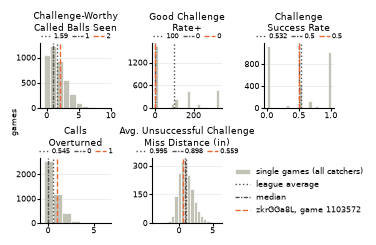

In [18]:
# figure for the one-page report: the half-width figure slot in section 2 of the LaTeX template (3.6 x 2.3 in).
# drawn at the size it prints, so the text isn't shrunk. the same lines as the single-game figure above
report_stats = {
    "challenge-worthy pitches": "Challenge-Worthy\nCalled Balls Seen",
    "GCR+": "Good Challenge\nRate+",
    "challenge success rate": "Challenge\nSuccess Rate",
    "calls overturned": "Calls\nOverturned",
    "unsuccessful challenge miss distance (in)": "Avg. Unsuccessful Challenge\nMiss Distance (in)",
}

with plt.rc_context({"font.size": 6, "axes.titlesize": 6.5, "xtick.labelsize": 5.5, "ytick.labelsize": 5.5,
                     "legend.fontsize": 5.5}):
    fig, axes = plt.subplots(2, 3, figsize=(3.6, 2.3))
    for ax, (stat, title) in zip(axes.flat, report_stats.items()):
        values = per_game[stat].dropna()
        # counts only take whole numbers, so they get one bar per value
        bins = np.arange(values.min() - 0.5, values.max() + 1.5) if (values % 1 == 0).all() else 20
        ax.hist(values, bins=bins, color="#c3c2b7", edgecolor="white", linewidth=0.5, label="single games (all catchers)")
        ax.axvline(catcher_eval.loc["league average", stat], color="#52514e", linestyle=":", linewidth=1,
                   label="league average")
        # a tighter dash-dot than "-.", so the pattern still shows in the short legend handles
        ax.axvline(values.median(), color="#52514e", linestyle=(0, (3, 1, 1, 1)), linewidth=1, label="median")
        ax.axvline(per_game.loc[(GAME, our_catcher), stat], color="#eb6834", linestyle="--", linewidth=1,
                   label=f"{our_catcher}, game {GAME}")
        ax.set_title(title, pad=9)
        ax.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=3))
        ax.tick_params(length=2, pad=1)
        ax.grid(axis="y", alpha=0.3, linewidth=0.5)
        ax.spines[["top", "right"]].set_visible(False)
        # each line's value in the line's own style, in a row between the title and the plot so it covers no bars
        # (a line with no value is left out)
        shown = [line for line in ax.get_lines() if pd.notna(line.get_xdata()[0])]
        ax.legend(shown, [f"{line.get_xdata()[0]:.3g}" for line in shown], loc="lower center", bbox_to_anchor=(0.5, 1),
                  ncol=len(shown), frameon=False, fontsize=5, handlelength=1.6, handletextpad=0.3, columnspacing=0.6,
                  borderpad=0)
    # the empty sixth panel holds the legend for the whole figure
    handles, labels = axes.flat[0].get_legend_handles_labels()
    axes.flat[5].axis("off")
    axes.flat[5].legend(handles, labels, loc="center", frameon=False)
    fig.supylabel("games", fontsize=6)
    fig.tight_layout(pad=0.3, h_pad=0.6, w_pad=0.6)
    fig.savefig("report_single_game_distributions.pdf")  # vector, for \includegraphics in the template
    plt.show()

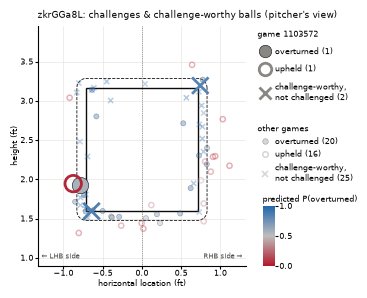

In [19]:
# figure for the one-page report: every ABS challenge our catcher made and every challenge-worthy pitch he didn't
# challenge, as in the interactive strike zone above (same pitches, colors and markers), redrawn at the size of the
# right-hand slot in section 2 (3.6 x 3.0 in). this game's pitches are drawn larger and in full color, other games faded
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

# the interactive plot's color scale: red = likely upheld, gray = toss-up, blue = likely overturned
p_cmap = LinearSegmentedColormap.from_list("p_overturned", ["#b2182b", "#bdbdbd", "#2166ac"])
pitches = caught[caught["decision"].isin(["overturned", "upheld", "not challenged"])]
in_game = pitches["game_id"] == GAME

with plt.rc_context({"font.size": 6, "axes.titlesize": 6.5, "axes.labelsize": 6, "xtick.labelsize": 5.5,
                     "ytick.labelsize": 5.5, "legend.fontsize": 5.5, "legend.title_fontsize": 5.5}):
    fig = plt.figure(figsize=(3.6, 3.0))
    # equal feet on both axes, so the zone keeps its real shape
    ax = fig.add_axes([0.11, 0.115, 0.58, 0.80])
    ax.set_xlim(-1.33, 1.33)
    ax.set_ylim(0.9, 3.95)
    ax.set_aspect("equal")

    # zone for the median batter, and the ABS edge one ball radius outside it (rounded corners)
    ax.add_patch(Rectangle((-PLATE_HALF, sz_bot), 2 * PLATE_HALF, sz_top - sz_bot, fill=False, edgecolor=INK,
                           linewidth=1))
    arc = np.linspace(0, np.pi / 2, 12)
    corners = [(PLATE_HALF, sz_top, 0), (-PLATE_HALF, sz_top, np.pi / 2), (-PLATE_HALF, sz_bot, np.pi),
               (PLATE_HALF, sz_bot, 1.5 * np.pi)]
    edge_x = np.concatenate([cx + BALL_R * np.cos(start + arc) for cx, _, start in corners])
    edge_z = np.concatenate([cz + BALL_R * np.sin(start + arc) for _, cz, start in corners])
    ax.plot(np.append(edge_x, edge_x[0]), np.append(edge_z, edge_z[0]), color=INK, linewidth=0.6, linestyle="--")
    ax.axvline(0, color=INK2, linewidth=0.5, linestyle=":")

    # filled = overturned, open = upheld, x = challenge-worthy but not challenged.
    # other games first (small, faded), then this game on top (large, thick-lined, full color)
    for game_mask, size, alpha, line in [(~in_game, 14, 0.35, 1.1), (in_game, 140, 1, 2)]:
        for kind in ["overturned", "upheld", "not challenged"]:
            pts = pitches[game_mask & (pitches["decision"] == kind)]
            colors = p_cmap(pts["p_success_g_challenge"])
            if kind == "overturned":
                ax.scatter(pts["plate_x"], pts["plate_z"], s=size, color=colors, edgecolor=INK, linewidth=0.4,
                           alpha=alpha, zorder=3)
            elif kind == "upheld":
                ax.scatter(pts["plate_x"], pts["plate_z"], s=size, facecolor="none", edgecolor=colors, linewidth=line,
                           alpha=alpha, zorder=3)
            else:
                ax.scatter(pts["plate_x"], pts["plate_z"], s=size, marker="x", color=colors, linewidth=line,
                           alpha=alpha, zorder=3)

    ax.text(-1.28, 0.97, "← LHB side", color=INK2, fontsize=5, ha="left", va="bottom")
    ax.text(1.28, 0.97, "RHB side →", color=INK2, fontsize=5, ha="right", va="bottom")
    ax.set_title(f"{our_catcher}: challenges & challenge-worthy balls (pitcher's view)", loc="left")
    ax.set_xlabel("horizontal location (ft)", labelpad=1)
    ax.set_ylabel("height (ft)", labelpad=1)
    ax.tick_params(length=2, pad=1)
    ax.grid(color="#e1e0d9", linewidth=0.4)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

    # legends to the right: marker shape and size in neutral gray (color is the model's prediction, in the colorbar)
    def key(kind, size, alpha, line):
        if kind == "not challenged":
            return Line2D([], [], linestyle="", marker="x", markersize=size, markeredgecolor="#898781",
                          markeredgewidth=line, alpha=alpha)
        filled = kind == "overturned"
        return Line2D([], [], linestyle="", marker="o", markersize=size, markerfacecolor="#898781" if filled else "none",
                      markeredgecolor=INK if filled else "#898781", markeredgewidth=0.4 if filled else line, alpha=alpha)
    # (the big markers of this game need more room between rows)
    for top, label, mask, size, alpha, line, spacing in [(0.915, f"game {GAME}", in_game, 9, 1, 2, 1.1),
                                                         (0.6, "other games", ~in_game, 4, 0.35, 1.1, 0.5)]:
        n = pitches[mask]["decision"].value_counts()
        fig.legend([key(kind, size, alpha, line) for kind in ["overturned", "upheld", "not challenged"]],
                   [f"overturned ({n.get('overturned', 0)})", f"upheld ({n.get('upheld', 0)})",
                    f"challenge-worthy,\nnot challenged ({n.get('not challenged', 0)})"],
                   title=label, loc="upper left", bbox_to_anchor=(0.71, top), frameon=False, alignment="left",
                   handletextpad=0.3, borderpad=0, labelspacing=spacing)
    cax = fig.add_axes([0.735, 0.115, 0.035, 0.2])
    colorbar = fig.colorbar(plt.cm.ScalarMappable(cmap=p_cmap, norm=plt.Normalize(0, 1)), cax=cax, ticks=[0, 0.5, 1])
    colorbar.outline.set_visible(False)
    cax.tick_params(length=2, pad=1)
    cax.set_title("predicted P(overturned)", loc="left", fontsize=5.5, pad=3)

    fig.savefig("report_challenge_locations.pdf")  # vector, for \includegraphics in the template
    plt.show()